# Treinamento e Validação do Modelo Preditivo de Defasagem Educacional (ENEM 2023)

Este notebook documenta o processo de treinamento, avaliação e exportação do modelo de Machine Learning (Classificação Binária) voltado à identificação precoce de alunos com risco de defasagem educacional a partir de seu perfil sociológico e demográfico.

* **Base de Dados:** `ENEM_2023_3ANO_ENCODED.parquet` (Concluintes do 3º ano do Ensino Médio regular, sem valores ausentes e com variáveis previamente codificadas).
* **Variável-Alvo ($y$):** `RISCO_DEFASAGEM` (`1` = Aluno no 1º quartil de desempenho / Alerta de atenção pedagógica; `0` = Desempenho regular esperado).
* **Desbalanceamento de Classes:** Como o risco foi definido pelo 1º quartil, a base possui proporção natural de **25% para a classe `1` (Risco)** e **75% para a classe `0` (Regular)**. O treinamento utiliza ponderação de classes (`class_weight='balanced'`) para maximizar a sensibilidade (*Recall*) na detecção dos alunos vulneráveis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    f1_score,
    recall_score,
    precision_score,
    accuracy_score
)

# Caso o arquivo esteja no seu Google Drive, descomente as duas linhas abaixo:
# from google.colab import drive
# drive.mount('/content/drive')

# Carregar o arquivo Parquet (ajuste o caminho se estiver numa pasta do Drive)
caminho_arquivo = 'ENEM_2023_3ANO_ENCODED.parquet'
df = pd.read_parquet(caminho_arquivo)

# Caso a coluna NOTA_MEDIA ainda exista no arquivo, garantimos sua remoção para evitar Data Leakage
if 'NOTA_MEDIA' in df.columns:
    df.drop(columns=['NOTA_MEDIA'], inplace=True)

print(f"Dimensões do Dataset: {df.shape[0]:,} linhas e {df.shape[1]} colunas.")
print("\nDistribuição da Variável-Alvo (RISCO_DEFASAGEM):")
print(df['RISCO_DEFASAGEM'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

Dimensões do Dataset: 681,357 linhas e 61 colunas.

Distribuição da Variável-Alvo (RISCO_DEFASAGEM):
RISCO_DEFASAGEM
0    75.0%
1    25.0%
Name: proportion, dtype: object


## 1. Separação entre Atributos Previsores ($X$) e Alvo ($y$)

A base é dividida na proporção de **80% para treinamento** e **20% para teste**. Utilizamos o parâmetro `stratify=y` para garantir que tanto o conjunto de treino quanto o de teste mantenham exatamente a mesma proporção de 25% de alunos em risco e 75% regulares.

In [2]:
# Separar variáveis preditoras (X) e variável-alvo (y)
X = df.drop(columns=['RISCO_DEFASAGEM'])
y = df['RISCO_DEFASAGEM']

# Divisão 80% Treino / 20% Teste com estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Registros de Treino: {X_train.shape[0]:,}")
print(f"Registros de Teste:  {X_test.shape[0]:,}")

Registros de Treino: 545,085
Registros de Teste:  136,272


## 2. Treinamento dos Modelos de Classificação

Para encontrar o melhor equilíbrio entre precisão e capacidade de detecção de alunos vulneráveis, treinamos e comparamos dois algoritmos baseados em árvores de decisão amplamente utilizados para dados tabulares socioeconômicos:
1. **LightGBM Classifier (`LGBMClassifier`):** Algoritmo de *Gradient Boosting* extremamente rápido para bases com centenas de milhares de linhas e excelente tratamento de variáveis ordinais/binárias.
2. **Random Forest Classifier (`RandomForestClassifier`):** Algoritmo de *Bagging* robusto contra *overfitting*, utilizado como linha de base (*baseline*) comparativa.

> **Nota sobre o `class_weight='balanced'`:** Se o modelo simplesmente chutasse que "nenhum aluno tem risco" (`0`), ele acertaria 75% das vezes (Acurácia de 75%), mas seria inútil para o gestor educacional. O balanceamento de pesos penaliza erros na classe minoritária (`1`), forçando o algoritmo a priorizar o **Recall (Sensibilidade)** — isto é, não deixar alunos com defasagem passarem despercebidos.

In [3]:
# 1. Treinar o LightGBM (Principal)
print("Treinando LightGBM...")
modelo_lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=8,
    num_leaves=63,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
modelo_lgbm.fit(X_train, y_train)

# 2. Treinar o Random Forest (Comparativo)
print("Treinando Random Forest...")
modelo_rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    min_samples_leaf=20,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
modelo_rf.fit(X_train, y_train)

print("Treinamento concluído com sucesso!")

Treinando LightGBM...
Treinando Random Forest...
Treinamento concluído com sucesso!


## 3. Avaliação e Validação dos Modelos

Avaliamos os modelos no conjunto de teste (20% dos dados nunca vistos pelo algoritmo) utilizando quatro métricas principais:
* **Recall (Sensibilidade da Classe 1):** De todos os alunos que realmente têm defasagem, quantos % o modelo conseguiu identificar? *(Métrica mais importante para o negócio pedagógico)*.
* **Precision (Precisão da Classe 1):** Dos alunos apontados em alerta pelo modelo, quantos % realmente ficaram no 1º quartil?
* **F1-Score:** Média harmônica entre Precision e Recall.
* **ROC-AUC:** Capacidade global do modelo de separar as duas classes (varia de 0.5 a 1.0).

==================== LightGBM Classifier ====================
                     precision    recall  f1-score   support

        0 - Regular       0.90      0.68      0.77    102205
1 - Risco Defasagem       0.44      0.77      0.56     34067

           accuracy                           0.70    136272
          macro avg       0.67      0.72      0.67    136272
       weighted avg       0.78      0.70      0.72    136272

ROC-AUC Score: 0.7959

==================== Random Forest Classifier ====================
                     precision    recall  f1-score   support

        0 - Regular       0.90      0.65      0.75    102205
1 - Risco Defasagem       0.42      0.78      0.55     34067

           accuracy                           0.68    136272
          macro avg       0.66      0.71      0.65    136272
       weighted avg       0.78      0.68      0.70    136272

ROC-AUC Score: 0.7833



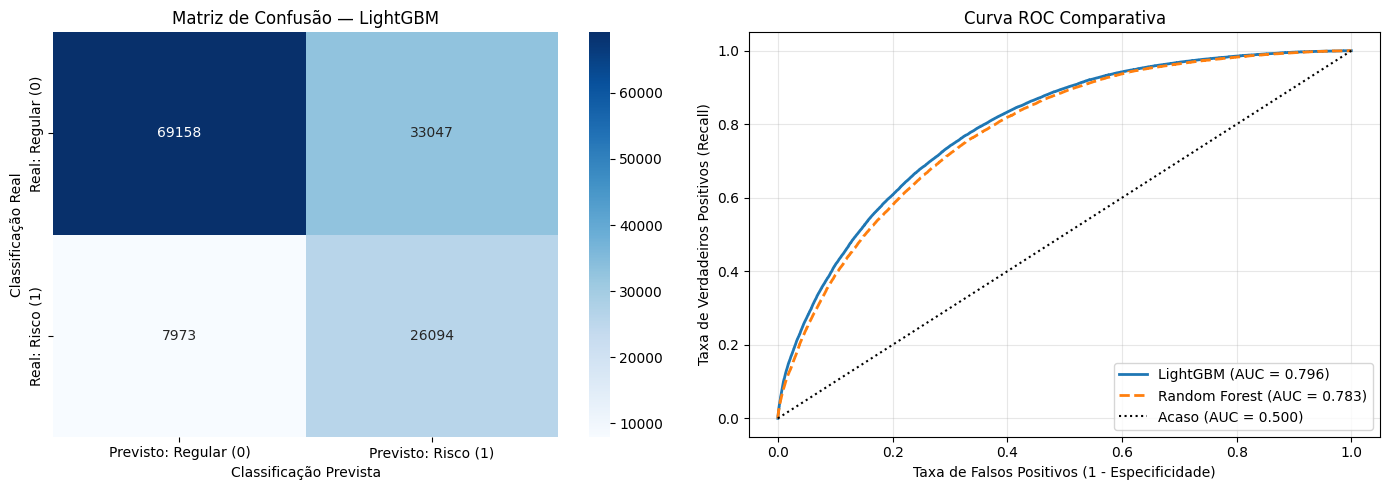

In [4]:
def avaliar_modelo(nome, modelo, X_teste, y_teste):
    y_pred = modelo.predict(X_teste)
    y_proba = modelo.predict_proba(X_teste)[:, 1]

    print(f"==================== {nome} ====================")
    print(classification_report(y_teste, y_pred, target_names=['0 - Regular', '1 - Risco Defasagem']))

    auc = roc_auc_score(y_teste, y_proba)
    print(f"ROC-AUC Score: {auc:.4f}\n")
    return y_pred, y_proba, auc

y_pred_lgbm, y_proba_lgbm, auc_lgbm = avaliar_modelo("LightGBM Classifier", modelo_lgbm, X_test, y_test)
y_pred_rf, y_proba_rf, auc_rf = avaliar_modelo("Random Forest Classifier", modelo_rf, X_test, y_test)

# Visualização Gráfica: Matriz de Confusão (LightGBM) e Curva ROC Comparativa
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Matriz de Confusão do LightGBM
cm = confusion_matrix(y_test, y_pred_lgbm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Previsto: Regular (0)', 'Previsto: Risco (1)'],
            yticklabels=['Real: Regular (0)', 'Real: Risco (1)'])
axes[0].set_title('Matriz de Confusão — LightGBM')
axes[0].set_ylabel('Classificação Real')
axes[0].set_xlabel('Classificação Prevista')

# Gráfico 2: Curva ROC
fpr_lgbm, tpr_lgbm, _ = roc_curve(y_test, y_proba_lgbm)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)

axes[1].plot(fpr_lgbm, tpr_lgbm, label=f'LightGBM (AUC = {auc_lgbm:.3f})', linewidth=2)
axes[1].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})', linewidth=2, linestyle='--')
axes[1].plot([0, 1], [0, 1], 'k:', label='Acaso (AUC = 0.500)')
axes[1].set_title('Curva ROC Comparativa')
axes[1].set_xlabel('Taxa de Falsos Positivos (1 - Especificidade)')
axes[1].set_ylabel('Taxa de Verdadeiros Positivos (Recall)')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Importância dos Atributos (Feature Importance)

Para validar se o aprendizado de máquina condiz com a realidade educacional, extraímos as 15 variáveis que mais influenciaram a decisão do modelo. Isso permite explicar aos gestores educacionais quais fatores sociológicos mais pesam no alerta de defasagem.

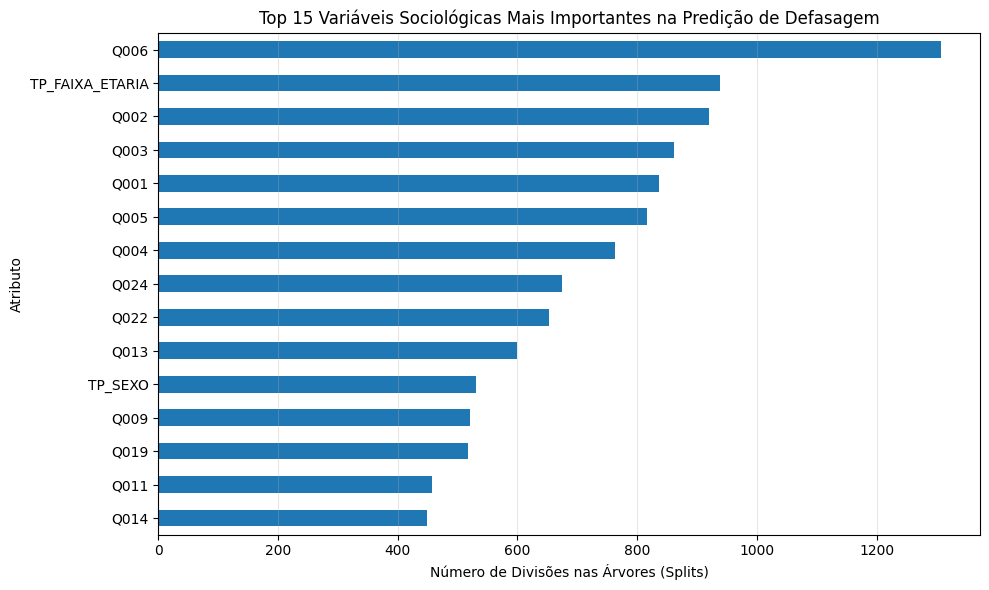

In [5]:
# Extrair importância das features do modelo vencedor (LightGBM)
importancias = pd.Series(modelo_lgbm.feature_importances_, index=X.columns)
top_15 = importancias.nlargest(15).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
top_15.plot(kind='barh', color='#1f77b4')
plt.title('Top 15 Variáveis Sociológicas Mais Importantes na Predição de Defasagem')
plt.xlabel('Número de Divisões nas Árvores (Splits)')
plt.ylabel('Atributo')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Exportação do Modelo para Produção (Backend / API)

Salvamos o modelo treinado (`modelo_risco_defasagem.joblib`) juntamente com a lista exata da ordem das colunas de entrada (`colunas_modelo.joblib`).

No backend da aplicação web, quando o gestor cadastrar um aluno na turma, a API garantirá que o DataFrame de entrada tenha exatamente essas colunas na mesma ordem, aplicando `modelo.predict_proba(dados_aluno)[:, 1]` para retornar a porcentagem de risco no Dashboard.

In [7]:
# 1. Salvar o modelo vencedor e a lista exata de colunas esperadas
artefato_deploy = {
    'modelo': modelo_lgbm,
    'colunas_features': list(X.columns),
    'metrica_auc_teste': round(auc_lgbm, 4)
}

joblib.dump(artefato_deploy, 'modelo_risco_defasagem.joblib', compress=3)
print("Arquivo 'modelo_risco_defasagem.joblib' salvo com sucesso!")

# 2. Simulação rápida de uso na API (Testando com 1 aluno real separado do conjunto de teste)
pacote = joblib.load('modelo_risco_defasagem.joblib')
modelo_carregado = pacote['modelo']
colunas_esperadas = pacote['colunas_features']

exemplo_aluno = X_test.iloc[[0]][colunas_esperadas]
classe_prevista = modelo_carregado.predict(exemplo_aluno)[0]
probabilidade_risco = modelo_carregado.predict_proba(exemplo_aluno)[0, 1] * 100

print("\n--- Simulação de Resposta da API para o Dashboard ---")
print(f"Alerta de Defasagem: {'SIM (Atenção Prioritária)' if classe_prevista == 1 else 'NÃO (Regular)'}")
print(f"Probabilidade calculada de defasagem: {probabilidade_risco:.1f}%")

Arquivo 'modelo_risco_defasagem.joblib' salvo com sucesso!

--- Simulação de Resposta da API para o Dashboard ---
Alerta de Defasagem: NÃO (Regular)
Probabilidade calculada de defasagem: 14.4%
